# 02 - Preprocessing

Build the filtered Summer/Snow pair table, assign geographic train/val/test splits, verify the shared RGB normalization, and precompute geographic hard negatives for training.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile
from scipy.spatial import KDTree
from omegaconf import OmegaConf

REPO_DIR = Path.cwd()
if not (REPO_DIR / "src").is_dir():
    REPO_DIR = REPO_DIR.parent
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.preprocessing.data_cleaner import load_pairs
from src.preprocessing.hard_negative_mining import precompute_hard_negatives
from src.preprocessing.normalization import normalize_rgb
from src.preprocessing.schema import HardNegatives, Pairs
from src.preprocessing.spatial import haversine_distance_m, lon_lat_to_unit_sphere
from src.preprocessing.splits import assign_geographic_splits

DATA_DIR = Path(os.environ.get("SEASONET_DIR", REPO_DIR / "data")).resolve()
ARTIFACTS_DIR = REPO_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(exist_ok=True)
PREPROCESSING_CFG = OmegaConf.load(REPO_DIR / "config/preprocessing_config.yaml")

In [2]:
MAX_CLOUD_COVER = PREPROCESSING_CFG.cleaning.max_cloud_cover
BLOCK_SIZE_M = PREPROCESSING_CFG.geographic_split.block_size_m
BUFFER_M = PREPROCESSING_CFG.geographic_split.buffer_m
SPLIT_FRACTIONS = dict(PREPROCESSING_CFG.geographic_split.fractions)
SETTINGS = f"clouds{MAX_CLOUD_COVER}_block{BLOCK_SIZE_M // 1000}km_buffer{BUFFER_M}m"

raw_pairs = load_pairs(DATA_DIR, max_cloud_cover=MAX_CLOUD_COVER)
pairs = assign_geographic_splits(
    raw_pairs,
    block_size_m=BLOCK_SIZE_M,
    buffer_m=BUFFER_M,
    fractions=SPLIT_FRACTIONS,
)
train_pairs = pairs[pairs[Pairs.SPLIT] == "train"].reset_index(drop=True)

print(f"pairs after cloud filter: {len(raw_pairs):,}")
print(f"pairs after split buffer: {len(pairs):,} ({1 - len(pairs) / len(raw_pairs):.1%} dropped)")
print(pairs[Pairs.SPLIT].value_counts())

pairs after cloud filter: 80,897
pairs after split buffer: 69,156 (14.5% dropped)
split
train    48087
test     14458
val       6611
Name: count, dtype: int64


## Geographic split check

SeasoNet's official splits are random over tiles, and Grid 2 is offset half a tile from Grid 1, so ~99% of official test tiles overlap a training tile. We split by ~10 km blocks instead and drop tiles within `BUFFER_M` of a tile in a higher-priority split (test > val > train). Overlapping tiles are at most ~1.7 km apart.

test -> nearest train tile: 2,012 m
val -> nearest train tile: 2,013 m
test -> nearest val tile: 2,013 m


Text(0.5, 1.0, 'Geographic splits')

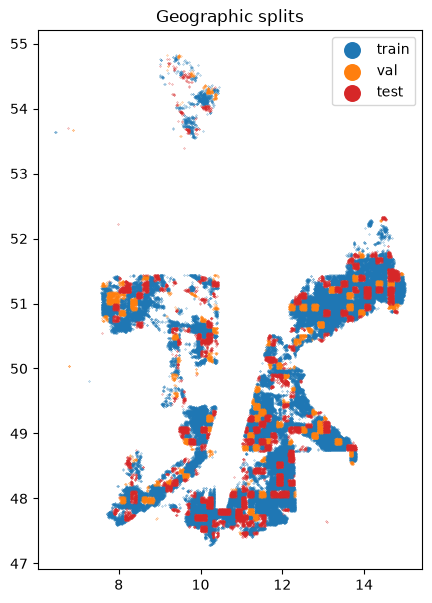

In [3]:
lon = pairs[Pairs.LONGITUDE_SUMMER].to_numpy()
lat = pairs[Pairs.LATITUDE_SUMMER].to_numpy()
xyz = lon_lat_to_unit_sphere(lon, lat)

for a, b in [("test", "train"), ("val", "train"), ("test", "val")]:
    in_a = (pairs[Pairs.SPLIT] == a).to_numpy()
    in_b = (pairs[Pairs.SPLIT] == b).to_numpy()
    _, nearest = KDTree(xyz[in_b]).query(xyz[in_a])
    dist = haversine_distance_m(lon[in_a], lat[in_a], lon[in_b][nearest], lat[in_b][nearest])
    print(f"{a} -> nearest {b} tile: {dist.min():,.0f} m")
    assert dist.min() > 1_700, f"{a} tiles overlap {b} tiles"

fig, ax = plt.subplots(figsize=(6, 7))
for split, color in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:red")]:
    s = pairs[pairs[Pairs.SPLIT] == split]
    ax.scatter(s[Pairs.LONGITUDE_SUMMER], s[Pairs.LATITUDE_SUMMER], s=0.05, color=color, label=split)
ax.set_aspect(1 / np.cos(np.deg2rad(51)))
ax.legend(markerscale=50)
ax.set_title("Geographic splits")

In [4]:
PAIRS_PATH = ARTIFACTS_DIR / f"pairs_{SETTINGS}.parquet"
pairs.to_parquet(PAIRS_PATH, index=False)
print(f"saved {len(pairs):,} pairs to {PAIRS_PATH.relative_to(REPO_DIR)}")

saved 69,156 pairs to artifacts/pairs_clouds50_block10km_buffer2000m.parquet


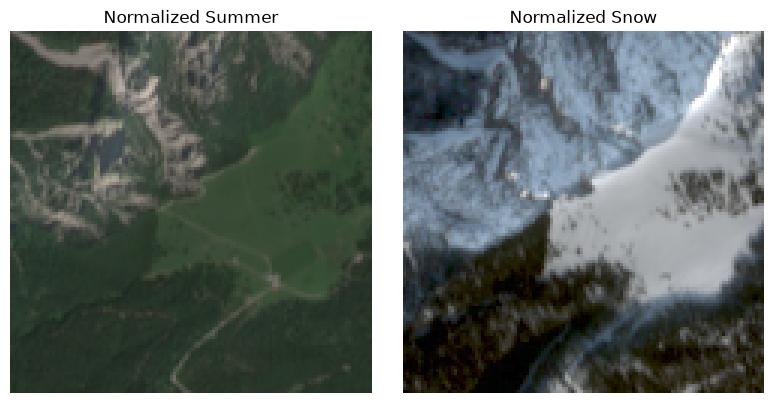

In [5]:
def load_rgb(rel_path):
    tile_dir = DATA_DIR / rel_path
    return tifffile.imread(next(tile_dir.glob("*_10m_RGB.tif")))

sample = train_pairs.sample(1, random_state=0).iloc[0]
summer_rgb = normalize_rgb(load_rgb(sample[Pairs.PATH_SUMMER]), gamma=True)
snow_rgb = normalize_rgb(load_rgb(sample[Pairs.PATH_SNOW]), gamma=True)

assert summer_rgb.dtype == np.float32
assert snow_rgb.dtype == np.float32
assert 0 <= summer_rgb.min() and summer_rgb.max() <= 1
assert 0 <= snow_rgb.min() and snow_rgb.max() <= 1

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(summer_rgb)
axes[0].set_title("Normalized Summer")
axes[1].imshow(snow_rgb)
axes[1].set_title("Normalized Snow")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

In [6]:
K = PREPROCESSING_CFG.hard_negatives.k
CANDIDATE_COUNT = PREPROCESSING_CFG.hard_negatives.candidate_count
EXCLUSION_RADIUS_M = PREPROCESSING_CFG.hard_negatives.exclusion_radius_m
OUTPUT_PATH = ARTIFACTS_DIR / f"hard_negatives_{SETTINGS}_k{K}_exclusion{EXCLUSION_RADIUS_M}m.parquet"

hard_negatives = precompute_hard_negatives(
    train_pairs,
    k=K,
    candidate_count=CANDIDATE_COUNT,
    exclusion_radius_m=EXCLUSION_RADIUS_M,
)
hard_negatives.to_parquet(OUTPUT_PATH, index=False)

per_anchor = hard_negatives.groupby(HardNegatives.ANCHOR_LOC_ID).size()
print(f"saved {len(hard_negatives):,} hard-negative relationships to {OUTPUT_PATH.relative_to(REPO_DIR)}")
print(f"Parquet size: {OUTPUT_PATH.stat().st_size / 1024 ** 2:.1f} MiB")
print(per_anchor.describe())

saved 2,404,350 hard-negative relationships to artifacts/hard_negatives_clouds50_block10km_buffer2000m_k50_exclusion2000m.parquet
Parquet size: 50.5 MiB
count    48087.0
mean        50.0
std          0.0
min         50.0
25%         50.0
50%         50.0
75%         50.0
max         50.0
dtype: float64
